Folder found: True
Recordings in metadata: 575

Recording 70 | length 20.00s | status on-on-off-off
     appliance event  sample  time_s
0       Laptop    ON   47520    1.58
1  Iron solder    ON  171859    5.73
2  Iron solder    ON  358474   11.95
3       Laptop   OFF  417506   13.92
4  Iron solder   OFF  483245   16.11


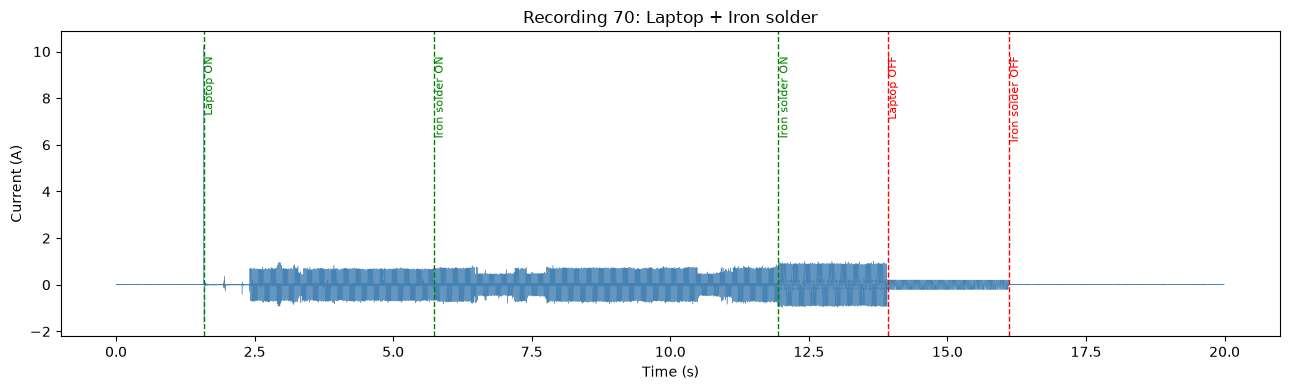

In [4]:
# ===== Setup =====
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path.home() / "Documents" / "10084619"
FS   = 30_000                      # 30 kHz sampling rate

print("Folder found:", DATA.exists())

# ===== Load aggregated metadata =====
with open(DATA / "metadata_aggregated.json") as f:
    meta_agg = json.load(f)

print("Recordings in metadata:", len(meta_agg))

# ===== Pick one recording =====
rec_id = "70"                      # change this to look at another recording
r = meta_agg[rec_id]

# ===== Load its waveform =====
w = pd.read_csv(DATA / "aggregated" / f"{rec_id}.csv",
                header=None, names=["current", "voltage"])
t = np.arange(len(w)) / FS         # time in seconds

# ===== Collect events into a table =====
events = []
for a in r["appliances"]:
    for s in re.findall(r"\d+", a["on"]):
        events.append({"appliance": a["type"], "event": "ON",  "sample": int(s)})
    for s in re.findall(r"\d+", a["off"]):
        events.append({"appliance": a["type"], "event": "OFF", "sample": int(s)})

ev = pd.DataFrame(events).sort_values("sample").reset_index(drop=True)
ev["time_s"] = (ev["sample"] / FS).round(2)

print(f"\nRecording {rec_id} | length {r['instances']['length']} | status {r['instances']['status']}")
print(ev)

# ===== Plot current with event lines =====
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, w["current"], linewidth=0.3, color="steelblue")

for _, e in ev.iterrows():
    color = "green" if e["event"] == "ON" else "red"
    ax.axvline(e["time_s"], color=color, linestyle="--", linewidth=1)
    ax.text(e["time_s"], ax.get_ylim()[1] * 0.9, f" {e['appliance']} {e['event']}",
            color=color, fontsize=8, rotation=90, va="top")

ax.set_title(f"Recording {rec_id}: " + " + ".join(a["type"] for a in r["appliances"]))
ax.set_xlabel("Time (s)")
ax.set_ylabel("Current (A)")
plt.tight_layout()
plt.show()

One Recoding of WaveForm

In [7]:
import json
from pathlib import Path
import pandas as pd

DATA = Path.home() / "Documents" / "10084619"

with open(DATA / "metadata_aggregated.json") as f:
    meta_agg = json.load(f)

rec_id = "1"                                   # change to any id from "1" to "575"
r = meta_agg[rec_id]

# 1) The raw record, exactly as stored
print(json.dumps(r, indent=2))

# 2) The same record's appliances as a table (easier to read)
print("\nLocation:", r["location"])
print("Header:", r["header"])
print("Instances:", r["instances"])
pd.DataFrame(r["appliances"])

{
  "appliances": [
    {
      "brand": "Lasko cyclone",
      "current": "1.1 A",
      "load": "I",
      "manufacture_year": "",
      "model_number": "",
      "notes": "",
      "off": "[204316]",
      "on": "[37043]",
      "type": "Fan",
      "voltage": "120V",
      "wattage": ""
    },
    {
      "brand": "Dirt Devil",
      "current": "10A",
      "load": "I",
      "manufacture_year": "",
      "model_number": "",
      "notes": "",
      "off": "[169374]",
      "on": "[89785]",
      "type": "Vacuum",
      "voltage": "120V",
      "wattage": ""
    }
  ],
  "header": {
    "collection_time": "August, 2017",
    "notes": "",
    "sampling_frequency": "30000Hz"
  },
  "instances": {
    "length": "10.00s",
    "status": "on-on-off-off"
  },
  "location": "CMU lab"
}

Location: CMU lab
Header: {'collection_time': 'August, 2017', 'notes': '', 'sampling_frequency': '30000Hz'}
Instances: {'length': '10.00s', 'status': 'on-on-off-off'}


,brand,current,load,manufacture_year,model_number,notes,off,on,type,voltage,wattage
0,Lasko cyclone,1.1 A,I,,,,[204316],[37043],Fan,120V,
1,Dirt Devil,10A,I,,,,[169374],[89785],Vacuum,120V,


In [8]:
import re
import json
from pathlib import Path
import pandas as pd

DATA = Path.home() / "Documents" / "10084619"

with open(DATA / "metadata_aggregated.json") as f:
    meta_agg = json.load(f)

def event_times(rec_id):
    r = meta_agg[str(rec_id)]

    # Sample rate from this file's metadata, e.g. "30000Hz" -> 30000
    fs = int(re.findall(r"\d+", r["header"]["sampling_frequency"])[0])

    rows = []
    for a in r["appliances"]:
        for s in re.findall(r"\d+", a["on"]):
            rows.append({"appliance": a["type"], "event": "ON",  "sample": int(s)})
        for s in re.findall(r"\d+", a["off"]):
            rows.append({"appliance": a["type"], "event": "OFF", "sample": int(s)})

    ev = pd.DataFrame(rows).sort_values("sample").reset_index(drop=True)
    ev["time_s"] = (ev["sample"] / fs).round(3)      # sample number -> seconds

    print(f"File {rec_id}.csv | sample rate {fs} Hz | length {r['instances']['length']}")
    return ev

event_times(1)          # change the number to any file from 1 to 575

File 1.csv | sample rate 30000 Hz | length 10.00s


,appliance,event,sample,time_s
0,Fan,ON,37043,1.235
1,Vacuum,ON,89785,2.993
2,Vacuum,OFF,169374,5.646
3,Fan,OFF,204316,6.811
